# 11 — Frozen global model: train, validation, and test backtest

This notebook reconstructs the frozen 58-feature global ridge model across the four annual out-of-time folds.

For a test year (t):

- **Train** is the sampled rolling five-year window ending before (t), evaluated in-sample after fitting. It is an optimistic fit diagnostic.
- **Validation** is year (t-1), predicted by a model trained on the five years ending before (t-1). This was the sample used to choose the ridge penalty.
- **Test** is the full year (t), predicted after refitting through the end of (t-1). It is the relevant backtest estimate.

Validation and test therefore represent genuine forward observations, while train does not. The target remains closing-auction volume; estimation uses the log residual relative to the lagged 20-auction median and reconstructs forecasts in shares.

In [1]:
from pathlib import Path
import json
import sys
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.5f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 130})

cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [cwd, *cwd.parents] if (p / "blackrock_data").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate blackrock_data.")
sys.path.insert(0, str(PROJECT_ROOT))

from notebooks.modeling_utils import (
    fit_preprocessor, apply_preprocessor, fit_ridge, predict_ridge, forecast_metrics
)

PANEL = PROJECT_ROOT / "outputs" / "eda" / "05_feature_engineering" / "enriched_daily_panel.parquet"
PRIOR_OUT = PROJECT_ROOT / "outputs" / "eda" / "09_global_finalists"
PREDICTIONS = PRIOR_OUT / "predictions"
OUT = PROJECT_ROOT / "outputs" / "eda" / "11_frozen_global_backtest"
OUT.mkdir(parents=True, exist_ok=True)

with open(PRIOR_OUT / "frozen_global_benchmark.json") as handle:
    SPEC = json.load(handle)
CHAMPION = SPEC["champion"]
FEATURES = SPEC["features"]

BOOLEAN_ALL = [
    "auction_spike_lag1", "is_monday", "is_friday",
    "is_first_trading_day_month", "is_last_trading_day_month",
    "is_last_3_trading_days_month", "is_last_5_trading_days_month",
    "is_last_trading_day_quarter", "is_last_3_trading_days_quarter",
    "is_last_5_trading_days_quarter", "is_last_trading_day_year",
    "monthly_options_expiry", "quarterly_options_expiry",
    "after_long_market_gap", "before_long_market_gap", "is_early_close",
    "early_close_month_end_window", "expiry_month_end_window",
]
CATEGORICAL_ALL = ["month", "day_of_week"]
BOOLEAN_FEATURES = [f for f in FEATURES if f in BOOLEAN_ALL]
CATEGORICAL_FEATURES = [f for f in FEATURES if f in CATEGORICAL_ALL]
CONTINUOUS_FEATURES = [f for f in FEATURES if f not in BOOLEAN_FEATURES and f not in CATEGORICAL_FEATURES]

TEST_YEARS = [2022, 2023, 2024, 2025]
TUNE_ROWS = 250_000
VALIDATION_ROWS = 120_000
REFIT_ROWS = 350_000
SEED = 20261012
CONTEXT = ["date", "permno", "auction_volume", "log1p_auction_volume", "median20_auction_volume"]
QUERY_COLUMNS = list(dict.fromkeys(CONTEXT + FEATURES))
QUOTED_COLUMNS = ", ".join(f'"{c}"' for c in QUERY_COLUMNS)

con = duckdb.connect()
con.execute("PRAGMA threads=4")

def sql(query):
    return con.execute(query).df()

def load_period(start_date, end_date, sample_rows=None, seed=SEED):
    sample_clause = f"USING SAMPLE {sample_rows} ROWS (reservoir, {seed})" if sample_rows else ""
    return sql(f"""
        SELECT * FROM (
            SELECT {QUOTED_COLUMNS} FROM read_parquet('{PANEL}')
            WHERE eligible_target AND date >= DATE '{start_date}' AND date < DATE '{end_date}'
        ) {sample_clause}
    """)

def fit_and_score(train, score, x_train, x_score, strength):
    fallback = float(np.median(train["auction_volume"]))
    train_base = train["median20_auction_volume"].fillna(fallback).to_numpy(dtype=float)
    score_base = score["median20_auction_volume"].fillna(fallback).to_numpy(dtype=float)
    target = train["log1p_auction_volume"].to_numpy(dtype=float) - np.log1p(train_base)
    coefficients = fit_ridge(x_train, target, strength)
    predicted_log = predict_ridge(x_score, coefficients) + np.log1p(score_base)
    lo, hi = np.quantile(train["log1p_auction_volume"].to_numpy(dtype=float), [0.001, 0.999])
    return np.maximum(np.expm1(np.clip(predicted_log, lo, hi)), 0)

lambda_history = pd.read_csv(PRIOR_OUT / "global_finalist_lambda_validation.csv")
selected_lambdas = (
    lambda_history[lambda_history["candidate"] == CHAMPION]
    .sort_values(["test_year", "validation_rmse_log"])
    .groupby("test_year", as_index=False).first()
    .set_index("test_year")["ridge_strength"].to_dict()
)
print(CHAMPION, selected_lambdas)

rolling5_residual_auction_calendar_liquidity {2022: 0.0001, 2023: 0.0001, 2024: 1e-07, 2025: 0.0001}


## Reconstruct fold-level performance

In [2]:
rows = []

for test_year in TEST_YEARS:
    print(f"Reconstructing fold ending in test year {test_year}...")
    validation_year = test_year - 1
    strength = selected_lambdas[test_year]

    # Validation model: trained strictly before the validation year.
    tune = load_period(f"{validation_year - 5}-01-01", f"{validation_year}-01-01",
                       TUNE_ROWS, SEED + test_year + len("rolling5"))
    validation = load_period(f"{validation_year}-01-01", f"{test_year}-01-01",
                             VALIDATION_ROWS, SEED + 100 + test_year + len("rolling5"))
    x_tune, prep_tune = fit_preprocessor(
        tune, CONTINUOUS_FEATURES, BOOLEAN_FEATURES, CATEGORICAL_FEATURES
    )
    x_validation = apply_preprocessor(
        validation, prep_tune, CONTINUOUS_FEATURES, BOOLEAN_FEATURES, CATEGORICAL_FEATURES
    )
    pred_validation = fit_and_score(tune, validation, x_tune, x_validation, strength)
    rows.append({
        "test_year": test_year, "split": "Validation", "period": str(validation_year),
        "ridge_strength": strength,
        **forecast_metrics(validation["auction_volume"], pred_validation),
    })

    # Final fold model: train metric is in-sample; test comes from the saved full-year forecast.
    train = load_period(f"{test_year - 5}-01-01", f"{test_year}-01-01",
                        REFIT_ROWS, SEED + 200 + test_year + len("rolling5"))
    x_train, prep_train = fit_preprocessor(
        train, CONTINUOUS_FEATURES, BOOLEAN_FEATURES, CATEGORICAL_FEATURES
    )
    pred_train = fit_and_score(train, train, x_train, x_train, strength)
    rows.append({
        "test_year": test_year, "split": "Train (in-sample)",
        "period": f"{test_year - 5}–{test_year - 1}", "ridge_strength": strength,
        **forecast_metrics(train["auction_volume"], pred_train),
    })

    test_path = PREDICTIONS / f"global_finalist_predictions_{test_year}.parquet"
    test = sql(f"SELECT auction_volume, \"{CHAMPION}\" AS prediction "
               f"FROM read_parquet('{test_path}')")
    rows.append({
        "test_year": test_year, "split": "Test", "period": str(test_year),
        "ridge_strength": strength,
        **forecast_metrics(test["auction_volume"], test["prediction"]),
    })

    del tune, validation, train, test, x_tune, x_validation, x_train

backtest = pd.DataFrame(rows)
split_order = ["Train (in-sample)", "Validation", "Test"]
backtest["split"] = pd.Categorical(backtest["split"], split_order, ordered=True)
backtest = backtest.sort_values(["test_year", "split"])
backtest.to_csv(OUT / "frozen_global_train_validation_test_metrics.csv", index=False)
display(backtest)

Reconstructing fold ending in test year 2022...


Reconstructing fold ending in test year 2023...


Reconstructing fold ending in test year 2024...


Reconstructing fold ending in test year 2025...


,test_year,split,period,ridge_strength,observations,mae_raw,wape,mae_log,rmse_log,spearman,aggregate_bias
1,2022,Train (in-sample),2017–2021,0.00010,350000,"76,577.97792",0.43897,0.43950,0.61525,0.93270,-0.15680
0,2022,Validation,2021,0.00010,120000,"77,868.96530",0.43247,0.41798,0.59955,0.93643,-0.15945
2,2022,Test,2022,0.00010,328634,"74,158.28669",0.38106,0.36377,0.53351,0.94896,-0.14441
4,2023,Train (in-sample),2018–2022,0.00010,350000,"79,428.66300",0.42257,0.41795,0.59007,0.93601,-0.15148
3,2023,Validation,2022,0.00010,120000,"73,047.15538",0.37647,0.36435,0.53455,0.94863,-0.14575
5,2023,Test,2023,0.00010,318679,"81,455.03182",0.36974,0.33481,0.48366,0.95623,-0.14165
7,2024,Train (in-sample),2019–2023,0.00000,350000,"79,879.51714",0.40612,0.39146,0.55966,0.94252,-0.14011
6,2024,Validation,2023,0.00000,120000,"82,871.69888",0.37335,0.33360,0.48164,0.95646,-0.14261
8,2024,Test,2024,0.00000,316212,"91,583.78589",0.35322,0.31465,0.44576,0.95943,-0.14528
10,2025,Train (in-sample),2020–2024,0.00010,350000,"83,200.47395",0.38895,0.36875,0.53381,0.94844,-0.13516


## Graphical comparison

Lower is better for log RMSE, log MAE, WAPE, and the absolute value of aggregate bias. Higher is better for Spearman rank correlation. The vertical distance between train and forward splits is a generalization gap, while changes across folds also reflect changing market conditions and coverage.

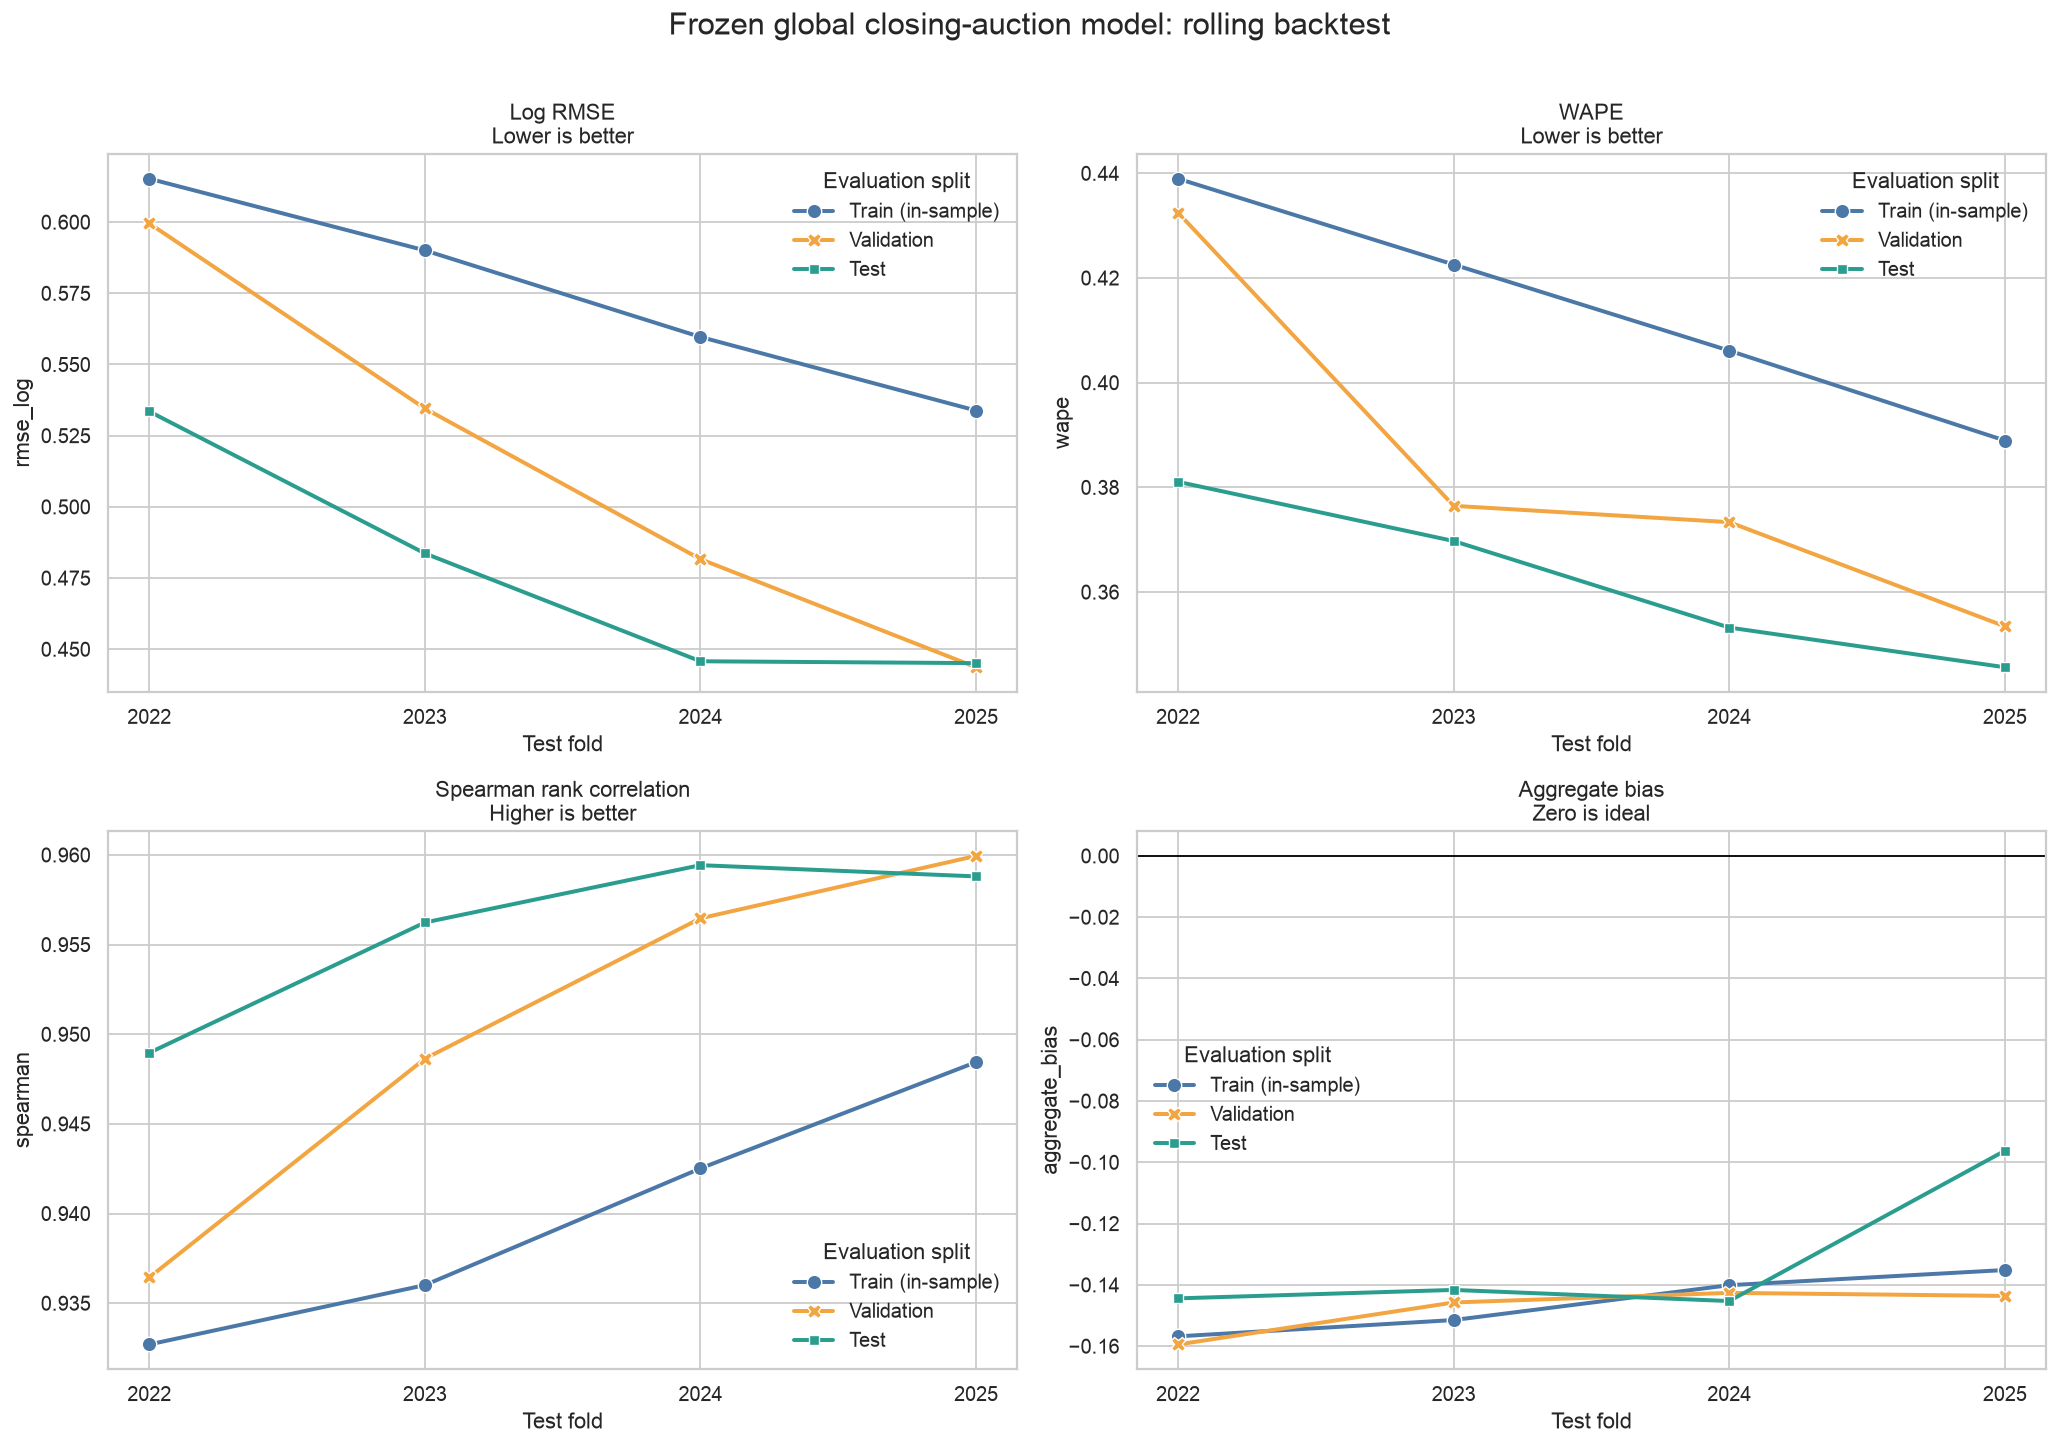

In [3]:
palette = {"Train (in-sample)": "#4C78A8", "Validation": "#F2A541", "Test": "#2A9D8F"}
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

panels = [
    ("rmse_log", "Log RMSE", "Lower is better"),
    ("wape", "WAPE", "Lower is better"),
    ("spearman", "Spearman rank correlation", "Higher is better"),
    ("aggregate_bias", "Aggregate bias", "Zero is ideal"),
]
for ax, (metric, title, subtitle) in zip(axes.flat, panels):
    sns.lineplot(data=backtest, x="test_year", y=metric, hue="split", style="split",
                 markers=True, dashes=False, linewidth=2.2, markersize=8,
                 palette=palette, hue_order=split_order, style_order=split_order, ax=ax)
    if metric == "aggregate_bias":
        ax.axhline(0, color="black", linewidth=1)
    ax.set_title(f"{title}\n{subtitle}")
    ax.set_xlabel("Test fold")
    ax.set_xticks(TEST_YEARS)
    ax.legend(frameon=False, title="Evaluation split")

fig.suptitle("Frozen global closing-auction model: rolling backtest", fontsize=17, y=1.01)
fig.tight_layout()
figure_path = OUT / "frozen_global_train_validation_test_backtest.png"
fig.savefig(figure_path, bbox_inches="tight")
plt.show()

## Generalization gaps

In [4]:
pivot = backtest.pivot(index="test_year", columns="split", values=["rmse_log", "wape"])
gaps = pd.DataFrame({
    "test_year": pivot.index,
    "validation_minus_train_rmse": pivot[("rmse_log", "Validation")].to_numpy()
        - pivot[("rmse_log", "Train (in-sample)")].to_numpy(),
    "test_minus_train_rmse": pivot[("rmse_log", "Test")].to_numpy()
        - pivot[("rmse_log", "Train (in-sample)")].to_numpy(),
    "validation_minus_train_wape": pivot[("wape", "Validation")].to_numpy()
        - pivot[("wape", "Train (in-sample)")].to_numpy(),
    "test_minus_train_wape": pivot[("wape", "Test")].to_numpy()
        - pivot[("wape", "Train (in-sample)")].to_numpy(),
})
gaps.to_csv(OUT / "frozen_global_generalization_gaps.csv", index=False)
display(gaps)

artifacts = pd.DataFrame({
    "artifact": ["Backtest metrics", "Generalization gaps", "Backtest figure"],
    "path": [
        OUT / "frozen_global_train_validation_test_metrics.csv",
        OUT / "frozen_global_generalization_gaps.csv",
        figure_path,
    ],
})
artifacts["path"] = artifacts["path"].astype(str)
artifacts.to_csv(OUT / "artifact_manifest.csv", index=False)
display(artifacts)

,test_year,validation_minus_train_rmse,test_minus_train_rmse,validation_minus_train_wape,test_minus_train_wape
0,2022,-0.01570,-0.08174,-0.00650,-0.05791
1,2023,-0.05552,-0.10641,-0.04609,-0.05282
2,2024,-0.07802,-0.11390,-0.03276,-0.05290
3,2025,-0.09015,-0.08869,-0.03549,-0.04331


,artifact,path
0,Backtest metrics,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
1,Generalization gaps,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
2,Backtest figure,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
